WORKFLOW
1. Load clean speech
    - Inspect their sampling rates, lengths, and amplitudes. Convert recordings to a common sampling rate if needed.
    - Plot the clean speech waveform and spectrogram.
2. Generate noisy speech
    - Add synthetic noise to the original clean recordings (eg. white gaussian noise, babble noise?)
3. Divide signal into frames
    - Speech is non-stationary --> its statistical characteristics change over time
    - But speech can be treated as roughly stationary within short frames
    - Can use short-time Fourier transform (STFT) with initial configurations:
        - Sampling frequency
        - Frame duration
        - Frame length
        - Overlap
        - Window
        - FFT length
4. Estimate noise and speech PSD
    - Estimate the noise power spectrum by averaging the squared STFT magnitues across noise-only frames
5. Apply enhancement algorithms
6. Evaluate performance
7. Compare the algorithms

In [1]:
# Import libraries
import numpy as np
import scipy
import matplotlib.pyplot as plt
import soundfile as sf
import librosa

In [2]:
# Load clean speech
clean_speech, fs = sf.read("clean speech.wav")

# Load noise signals
babble_noise, fs_babble = sf.read("babble noise.wav")
stationary_noise, fs_stationary = sf.read(
    "stationary speech-shaped noise.wav"
)

# Display information
print("Clean speech:")
print("Sampling rate:", fs)
print("Duration:", len(clean_speech) / fs, "seconds")
print("Shape:", clean_speech.shape)

print("\nBabble noise:")
print("Sampling rate:", fs_babble)
print("Duration:", len(babble_noise) / fs_babble, "seconds")

print("\nStationary noise:")
print("Sampling rate:", fs_stationary)
print("Duration:", len(stationary_noise) / fs_stationary, "seconds")

Clean speech:
Sampling rate: 16000
Duration: 36.1034375 seconds
Shape: (577655,)

Babble noise:
Sampling rate: 16000
Duration: 37.5000625 seconds

Stationary noise:
Sampling rate: 16000
Duration: 90.0 seconds


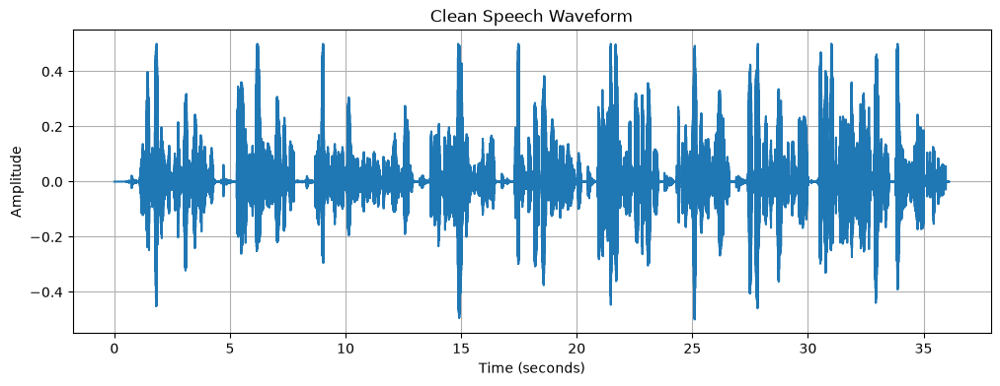

In [3]:
# Time axis
time = np.arange(len(clean_speech)) / fs

plt.figure(figsize=(12, 4))

plt.plot(time, clean_speech)
# plt.plot(time, babble_noise)
# plt.plot(time, stationary_noise)

plt.title("Clean Speech Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.show()

c:\Users\laura\Github\Speech_Enhancement\.venv\Lib\site-packages\matplotlib\axes\_axes.py:8647: RuntimeWarning: divide by zero encountered in log10
  Z = 10. * np.log10(spec)


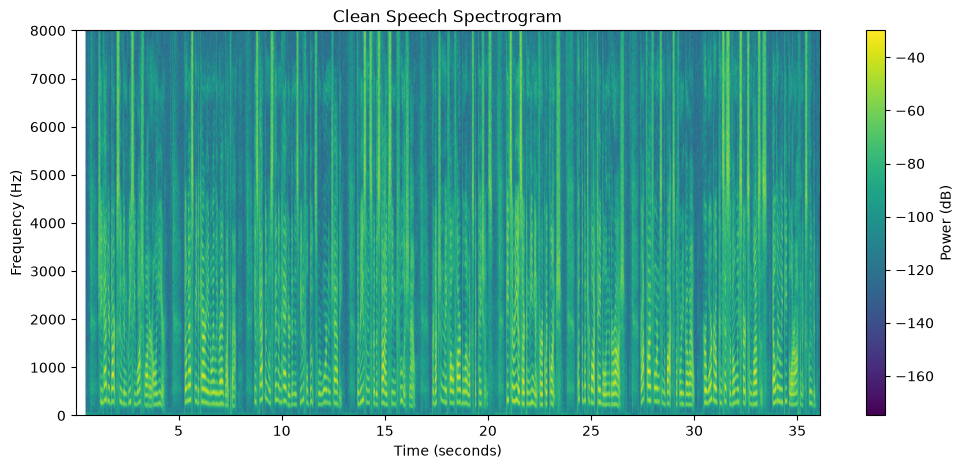

In [4]:
plt.figure(figsize=(12, 5))

plt.specgram(
    clean_speech,
    Fs=fs,
    NFFT=512,
    noverlap=256,
    cmap="viridis"
)

plt.title("Clean Speech Spectrogram")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.colorbar(label="Power (dB)")

plt.show()

- All three audio recordings have the same sampling frequency = 16000Hz (no need to resample)
- Clean speech waveform : Can identify periods of speech activity and short pauses between utterances.
- Spectrogram : 
    - Horizontal bands: Harmonics associated with voiced speech.
    - Vertical patterns: Rapid changes in speech, such as consonants and transitions.
    - Concentrated energy below approximately 4,000 Hz: Much of the visible speech energy lies in the lower-frequency range.

In [5]:
# Add noise to clean speech at a specified SNR
# Function to generate noisy speech
def add_noise(clean, noise, target_snr_db):

    # Make sure noise is long enough
    if len(noise) < len(clean):
        repeats = int(np.ceil(len(clean) / len(noise)))
        noise = np.tile(noise, repeats)

    # Match noise length to speech
    noise = noise[:len(clean)]

    # Calculate average signal power
    speech_power = np.mean(clean**2)
    noise_power = np.mean(noise**2)

    # Calculate desired noise power
    target_noise_power = speech_power / (10**(target_snr_db / 10))

    # Scale noise
    scaling_factor = np.sqrt(target_noise_power / noise_power)

    scaled_noise = noise * scaling_factor

    # Add noise to clean speech
    noisy = clean + scaled_noise

    return noisy, scaled_noise

In [6]:
# Generate noisy speech
# Desired SNR
target_snr = 0

# Generate noisy speech
noisy_babble, scaled_babble = add_noise(
    clean_speech,
    babble_noise,
    target_snr
)

noisy_stationary, scaled_stationary = add_noise(
    clean_speech,
    stationary_noise,
    target_snr
)

print("Babble noise shape:", noisy_babble.shape)
print("Stationary noise shape:", noisy_stationary.shape)

Babble noise shape: (577655,)
Stationary noise shape: (577655,)


In [ ]:
# Verify SNR of the generated noisy speech
def calculate_snr(clean, noise):
    speech_power = np.mean(clean**2)
    noise_power = np.mean(noise**2)

    return 10 * np.log10(speech_power / noise_power)


print(
    "Babble SNR:",
    calculate_snr(clean_speech, scaled_babble),
    "dB"
)

print(
    "Stationary SNR:",
    calculate_snr(clean_speech, scaled_stationary),
    "dB"
)

Babble SNR: 0.0 dB
Stationary SNR: -4.821637332766436e-16 dB


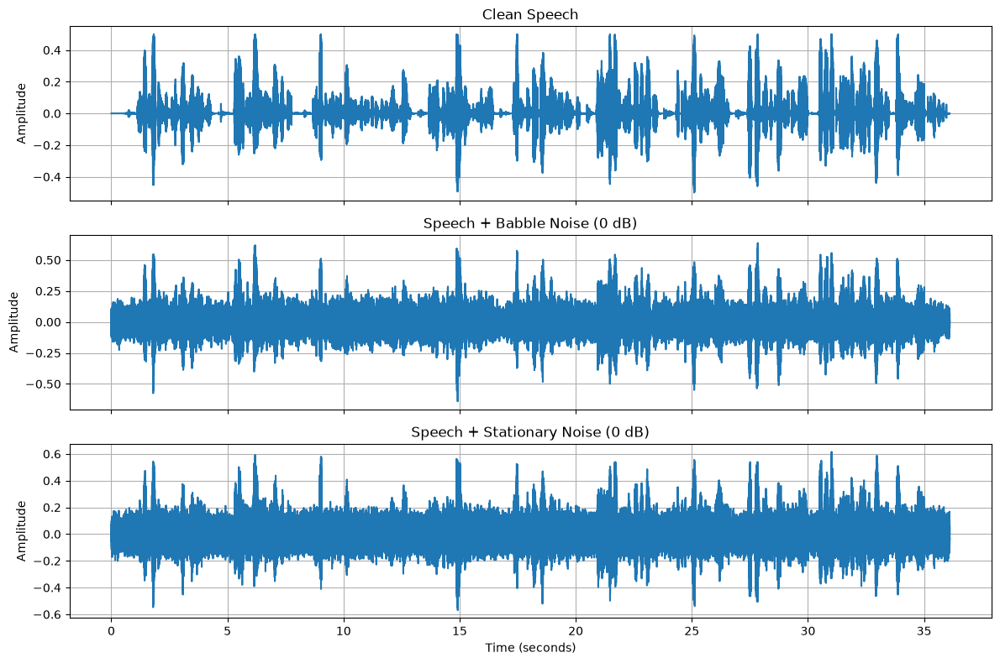

In [8]:
# Plot waveforms of clean and noisy speech
time = np.arange(len(clean_speech)) / fs

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

axes[0].plot(time, clean_speech)
axes[0].set_title("Clean Speech")

axes[1].plot(time, noisy_babble)
axes[1].set_title("Speech + Babble Noise (0 dB)")

axes[2].plot(time, noisy_stationary)
axes[2].set_title("Speech + Stationary Noise (0 dB)")

for ax in axes:
    ax.set_ylabel("Amplitude")
    ax.grid(True)

axes[-1].set_xlabel("Time (seconds)")

plt.tight_layout()
plt.show()

In [9]:
from IPython.display import Audio, display

print("Original clean speech:")
display(Audio(clean_speech, rate=fs))
# display(Audio(clean_speech[int(0*fs):int(0.4*fs)], rate=fs))

print("Speech with babble noise:")
display(Audio(noisy_babble, rate=fs))

print("Speech with stationary noise:")
display(Audio(noisy_stationary, rate=fs))

Original clean speech:


Speech with babble noise:


Speech with stationary noise:


Short-Time Fourier Transform (STFT)

In [10]:
# Define STFT parameters
from scipy.signal import stft, istft
import numpy as np
import matplotlib.pyplot as plt

# STFT parameters
nperseg = 512       # Frame length = 32 ms at 16 kHz
noverlap = 256      # 50% overlap
nfft = 512          # FFT length
window = "hann"

print("Frame duration:", nperseg / fs * 1000, "ms")
print("Overlap:", noverlap / nperseg * 100, "%")
print("Frequency resolution:", fs / nfft, "Hz")

Frame duration: 32.0 ms
Overlap: 50.0 %
Frequency resolution: 31.25 Hz


Output:
Frame duration: 32.0 ms
Overlap: 50.0 %
Frequency resolution: 31.25 Hz (FFT-bin spacing)

In [11]:
# Calculate the STFT
# Clean speech
f, t, S = stft(
    clean_speech,
    fs=fs,
    window=window,
    nperseg=nperseg,
    noverlap=noverlap,
    nfft=nfft
)

# Speech with babble noise
_, _, Y_babble = stft(
    noisy_babble,
    fs=fs,
    window=window,
    nperseg=nperseg,
    noverlap=noverlap,
    nfft=nfft
)

# Speech with stationary noise
_, _, Y_stationary = stft(
    noisy_stationary,
    fs=fs,
    window=window,
    nperseg=nperseg,
    noverlap=noverlap,
    nfft=nfft
)

print("Clean STFT shape:", S.shape)
print("Babble STFT shape:", Y_babble.shape)
print("Stationary STFT shape:", Y_stationary.shape)

Clean STFT shape: (257, 2258)
Babble STFT shape: (257, 2258)
Stationary STFT shape: (257, 2258)


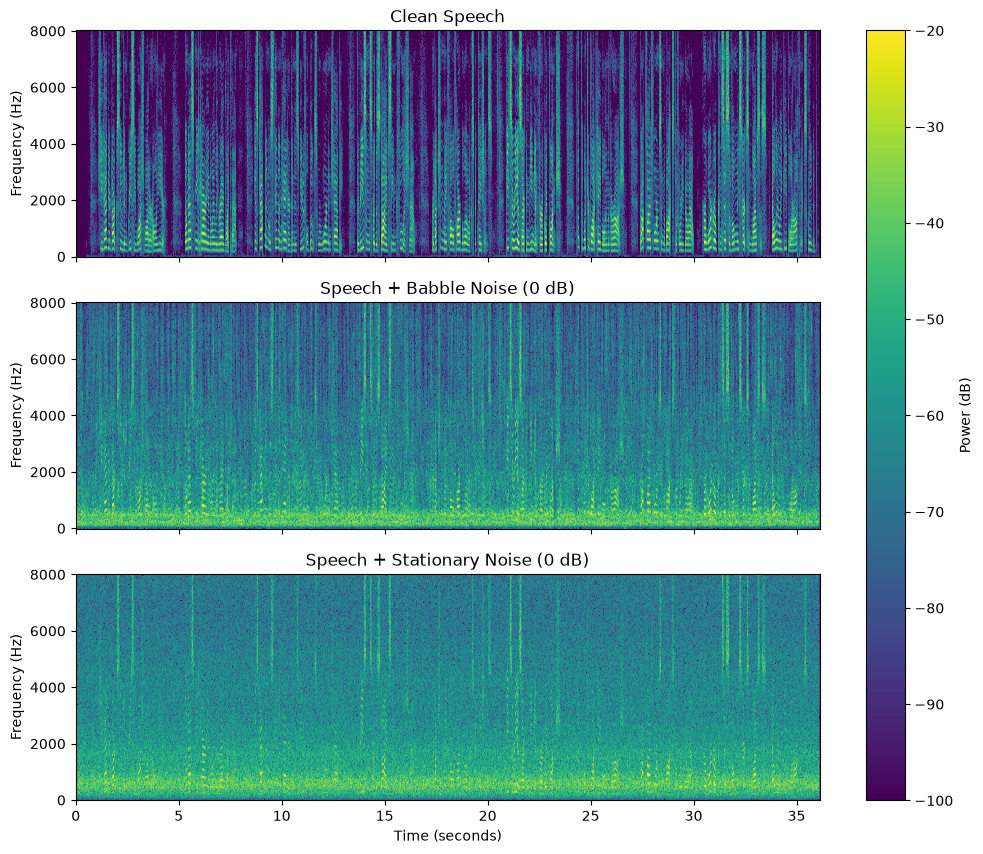

In [12]:
# Plot the spectrograms
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

signals = [
    (S, "Clean Speech"),
    (Y_babble, "Speech + Babble Noise (0 dB)"),
    (Y_stationary, "Speech + Stationary Noise (0 dB)")
]

for ax, (Z, title) in zip(axes, signals):

    power_db = 10 * np.log10(np.abs(Z)**2 + 1e-12)

    im = ax.pcolormesh(
        t,
        f,
        power_db,
        shading="auto",
        cmap="viridis",
        vmin=-100,
        vmax=-20
    )

    ax.set_title(title)
    ax.set_ylabel("Frequency (Hz)")

axes[-1].set_xlabel("Time (seconds)")

fig.colorbar(
    im,
    ax=axes,
    label="Power (dB)"
)

plt.show()

In [13]:
# Reconstruct clean speech using inverse STFT
_, reconstructed = istft(
    S,
    fs=fs,
    window=window,
    nperseg=nperseg,
    noverlap=noverlap,
    nfft=nfft
)

# Match original length
reconstructed = reconstructed[:len(clean_speech)]

# Reconstruction error
mse = np.mean((clean_speech - reconstructed)**2)

print("STFT reconstruction MSE:", mse)

STFT reconstruction MSE: 1.802178668666816e-34



STEP 4 : ESTIMATING SPEECH & NOISE PSDs
-----------------------------------------

In [14]:
# STFT of scaled babble noise
_, _, N_babble = stft(
    scaled_babble,
    fs=fs,
    window=window,
    nperseg=nperseg,
    noverlap=noverlap,
    nfft=nfft
)

# STFT of scaled stationary noise
_, _, N_stationary = stft(
    scaled_stationary,
    fs=fs,
    window=window,
    nperseg=nperseg,
    noverlap=noverlap,
    nfft=nfft
)

print("Babble noise STFT:", N_babble.shape)
print("Stationary noise STFT:", N_stationary.shape)

Babble noise STFT: (257, 2258)
Stationary noise STFT: (257, 2258)


In [15]:
# Estimate noise power spectra by averaging across time frames
psd_babble = np.mean(np.abs(N_babble)**2, axis=1)

psd_stationary = np.mean(np.abs(N_stationary)**2, axis=1)

print("Babble PSD shape:", psd_babble.shape)
print("Stationary PSD shape:", psd_stationary.shape)

Babble PSD shape: (257,)
Stationary PSD shape: (257,)


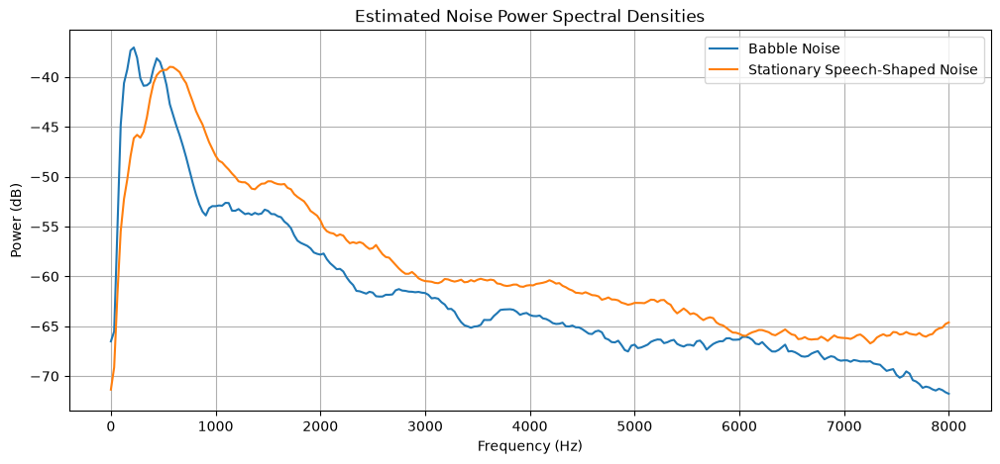

In [16]:
plt.figure(figsize=(12, 5))

plt.plot(
    f,
    10 * np.log10(psd_babble + 1e-12),
    label="Babble Noise"
)

plt.plot(
    f,
    10 * np.log10(psd_stationary + 1e-12),
    label="Stationary Speech-Shaped Noise"
)

plt.title("Estimated Noise Power Spectral Densities")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (dB)")
plt.legend()
plt.grid(True)

plt.show()

In [17]:
# Estimate speech PSD from noisy speech

eps = 1e-12 # very small value to avoid log(0)

speech_psd_babble = np.maximum(
    np.abs(Y_babble)**2 - psd_babble[:, None],
    0
)

speech_psd_stationary = np.maximum(
    np.abs(Y_stationary)**2 - psd_stationary[:, None],
    0
)

print("Speech PSD (babble):", speech_psd_babble.shape)
print("Speech PSD (stationary):", speech_psd_stationary.shape)

Speech PSD (babble): (257, 2258)
Speech PSD (stationary): (257, 2258)


STEP 5 : IMPLEMENT SPEECH ENHANCEMENT ALGORITHMS
------------------------------------------------

In [18]:
def wiener_filter(Y, speech_psd, noise_psd, eps=1e-12):

    # Wiener filter frequency response
    H = speech_psd / (
        speech_psd + noise_psd[:, None] + eps
    )

    # Apply filter
    S_hat = H * Y

    return S_hat, H

In [19]:
# Apply Wiener filtering
# Wiener filtering: babble noise
S_hat_babble, H_babble = wiener_filter(
    Y_babble,
    speech_psd_babble,
    psd_babble
)

# Wiener filtering: stationary noise
S_hat_stationary, H_stationary = wiener_filter(
    Y_stationary,
    speech_psd_stationary,
    psd_stationary
)

print("Babble enhanced STFT:", S_hat_babble.shape)
print("Stationary enhanced STFT:", S_hat_stationary.shape)

Babble enhanced STFT: (257, 2258)
Stationary enhanced STFT: (257, 2258)


In [20]:
# Reconstruct enhanced babble speech
_, enhanced_babble = istft(
    S_hat_babble,
    fs=fs,
    window=window,
    nperseg=nperseg,
    noverlap=noverlap,
    nfft=nfft
)

# Reconstruct enhanced stationary speech
_, enhanced_stationary = istft(
    S_hat_stationary,
    fs=fs,
    window=window,
    nperseg=nperseg,
    noverlap=noverlap,
    nfft=nfft
)

# Match original signal length
enhanced_babble = enhanced_babble[:len(clean_speech)]
enhanced_stationary = enhanced_stationary[:len(clean_speech)]

print("Enhanced babble shape:", enhanced_babble.shape)
print("Enhanced stationary shape:", enhanced_stationary.shape)

Enhanced babble shape: (577655,)
Enhanced stationary shape: (577655,)


In [21]:
print("Original clean speech:")
display(Audio(clean_speech, rate=fs, normalize=False))

print("Babble noise — Before enhancement:")
display(Audio(noisy_babble, rate=fs, normalize=False))

print("Babble noise — After Wiener filtering:")
display(Audio(enhanced_babble, rate=fs, normalize=False))

print("Stationary noise — Before enhancement:")
display(Audio(noisy_stationary, rate=fs, normalize=False))

print("Stationary noise — After Wiener filtering:")
display(Audio(enhanced_stationary, rate=fs, normalize=False))

Original clean speech:


Babble noise — Before enhancement:


Babble noise — After Wiener filtering:


Stationary noise — Before enhancement:


Stationary noise — After Wiener filtering:


COMMENTS ON THE AUDIO RESULTS:
- Babble noise
    - bcackground noise more quieter
    - speech somewhat easier to understand, some words/parts clearer than others
    - some distortion and unnatural sounds
- Stationary noise
    - background noise is quieter
    - lots of unnatural noise, weird static
    - a bit noiser still than the results of babble noise

In [22]:
def spectral_subtraction(Y, noise_psd, eps=1e-12):
    # Noisy speech power spectrum
    noisy_power = np.abs(Y)**2

    # Subtract estimated noise power
    clean_power = np.maximum(
        noisy_power - noise_psd[:, None],
        0
    )

    # Convert power to magnitude
    clean_magnitude = np.sqrt(clean_power)

    # Preserve noisy phase
    noisy_phase = np.exp(1j * np.angle(Y))

    # Reconstruct enhanced STFT
    S_hat = clean_magnitude * noisy_phase

    return S_hat

In [23]:
# Apply spectral subtraction
S_sub_babble = spectral_subtraction(
    Y_babble,
    psd_babble
)

S_sub_stationary = spectral_subtraction(
    Y_stationary,
    psd_stationary
)

# Reconstruct audio
_, sub_babble = istft(
    S_sub_babble,
    fs=fs,
    window=window,
    nperseg=nperseg,
    noverlap=noverlap,
    nfft=nfft
)

_, sub_stationary = istft(
    S_sub_stationary,
    fs=fs,
    window=window,
    nperseg=nperseg,
    noverlap=noverlap,
    nfft=nfft
)

# Match original length
sub_babble = sub_babble[:len(clean_speech)]
sub_stationary = sub_stationary[:len(clean_speech)]

In [24]:
print("BABBLE NOISE")

print("Noisy speech:")
display(Audio(noisy_babble, rate=fs, normalize=False))

print("Wiener filtering:")
display(Audio(enhanced_babble, rate=fs, normalize=False))

print("Spectral subtraction:")
display(Audio(sub_babble, rate=fs, normalize=False))

BABBLE NOISE
Noisy speech:


Wiener filtering:


Spectral subtraction:


STEP 6 : EVALUATE ENHANCEMENT PERFORMANCE
------------------------------------------

In [25]:
def calculate_mse(clean, enhanced):
    return np.mean((clean - enhanced)**2)

In [26]:
def calculate_rmse(clean, enhanced):
    return np.sqrt(calculate_mse(clean, enhanced))

In [27]:
def calculate_output_snr(clean, enhanced):
    signal_power = np.mean(clean**2)
    error_power = np.mean((clean - enhanced)**2)

    return 10 * np.log10(
        signal_power / (error_power + 1e-20)
    )

In [28]:
import pandas as pd

results = []

signals = {
    "Babble": {
        "Noisy": noisy_babble,
        "Wiener": enhanced_babble,
        "Spectral Subtraction": sub_babble
    },
    "Stationary": {
        "Noisy": noisy_stationary,
        "Wiener": enhanced_stationary,
        "Spectral Subtraction": sub_stationary
    }
}

for noise_type, methods in signals.items():

    input_snr = calculate_output_snr(
        clean_speech,
        methods["Noisy"]
    )

    for method, signal in methods.items():

        output_snr = calculate_output_snr(
            clean_speech,
            signal
        )

        results.append({
            "Noise Type": noise_type,
            "Method": method,
            "MSE": calculate_mse(clean_speech, signal),
            "RMSE": calculate_rmse(clean_speech, signal),
            "Output SNR (dB)": output_snr,
            "SNR Improvement (dB)": output_snr - input_snr
        })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Noise Type,Method,MSE,RMSE,Output SNR (dB),SNR Improvement (dB)
0,Babble,Noisy,0.0029,0.0538,0.0000,0.0000
1,Babble,Wiener,0.0010,0.0311,4.7709,4.7709
2,Babble,Spectral Subtraction,0.0013,0.0363,3.4238,3.4238
3,Stationary,Noisy,0.0029,0.0538,-0.0000,0.0000
4,Stationary,Wiener,0.0008,0.0284,5.5528,5.5528
5,Stationary,Spectral Subtraction,0.0012,0.0342,3.9538,3.9538


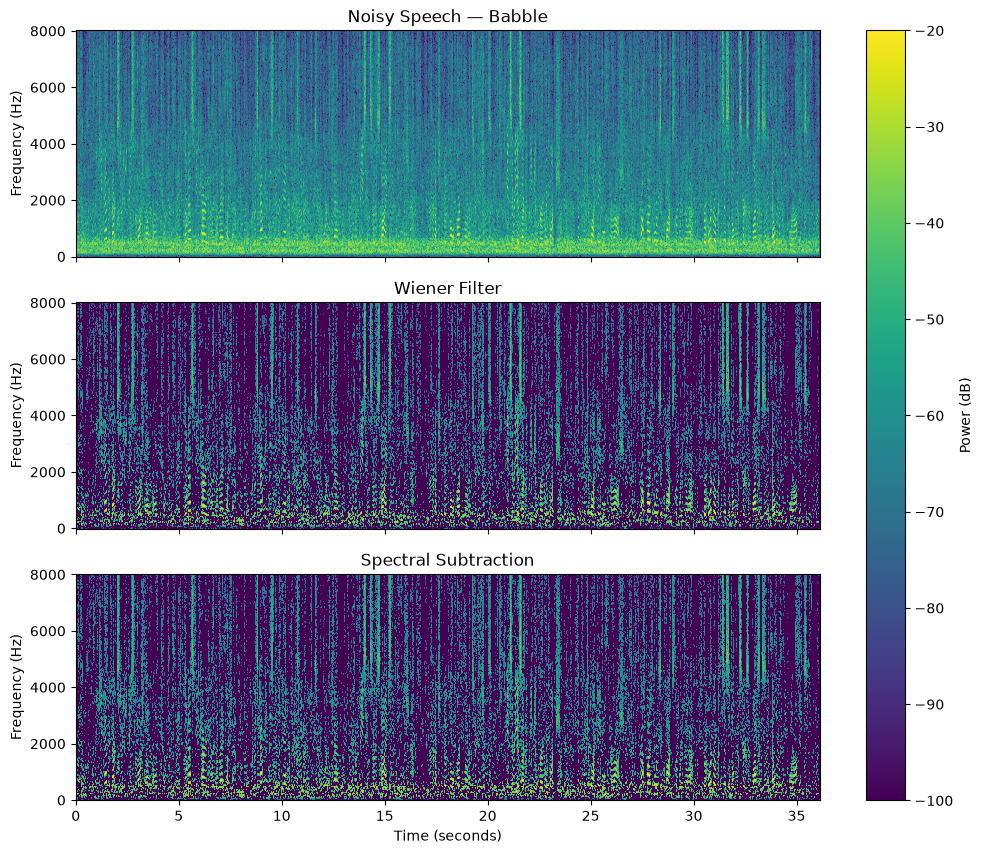

In [29]:
# Visualize the comparison
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

spectrograms = [
    (Y_babble, "Noisy Speech — Babble"),
    (S_hat_babble, "Wiener Filter"),
    (S_sub_babble, "Spectral Subtraction")
]

for ax, (Z, title) in zip(axes, spectrograms):

    power_db = 10 * np.log10(
        np.abs(Z)**2 + 1e-12
    )

    im = ax.pcolormesh(
        t,
        f,
        power_db,
        shading="auto",
        cmap="viridis",
        vmin=-100,
        vmax=-20
    )

    ax.set_title(title)
    ax.set_ylabel("Frequency (Hz)")

axes[-1].set_xlabel("Time (seconds)")

fig.colorbar(
    im,
    ax=axes,
    label="Power (dB)"
)

plt.show()

Wiener gain range: 0.0 0.9997261889137005
Spectral subtraction gain range: 0.0 0.9998630858347038
Mean difference: 5.61165676156322e-07


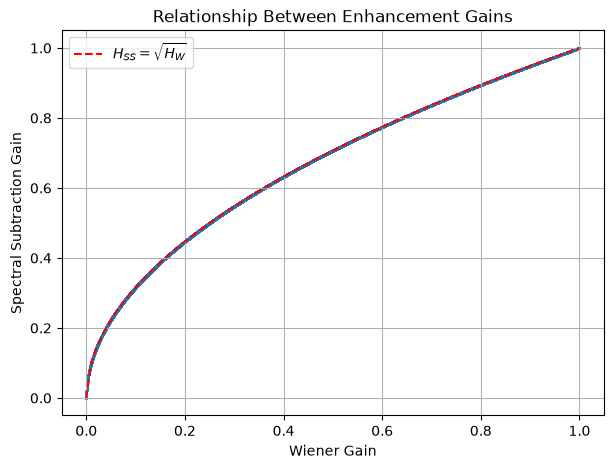

In [30]:
# VERIFYING THE RELATIONSHIP BETWEEN WIENER AND SPECTRAL SUBTRACTION GAINS
# Equivalent spectral subtraction gain
H_sub_babble = np.sqrt(
    np.maximum(
        1 - psd_babble[:, None] /
        (np.abs(Y_babble)**2 + 1e-12),
        0
    )
)

# Compare Wiener and spectral subtraction gains
print("Wiener gain range:",
      H_babble.min(), H_babble.max())

print("Spectral subtraction gain range:",
      H_sub_babble.min(), H_sub_babble.max())

# Compare the relationship between gains
difference = np.mean(
    np.abs(H_sub_babble - np.sqrt(H_babble))
)

print("Mean difference:", difference)

# Visualizing the relationship between Wiener and spectral subtraction gains
plt.figure(figsize=(7, 5))

plt.scatter(
    H_babble.flatten(),
    H_sub_babble.flatten(),
    s=1,
    alpha=0.1
)

x = np.linspace(0, 1, 100)

plt.plot(x, np.sqrt(x), "r--",
         label=r"$H_{SS}=\sqrt{H_W}$")

plt.xlabel("Wiener Gain")
plt.ylabel("Spectral Subtraction Gain")
plt.title("Relationship Between Enhancement Gains")
plt.legend()
plt.grid(True)

plt.show()

STEP 7 : IMPLEMENT REALISTIC WIENER FILTER
------------------------------------------
What's been done so far:
- Wiener filtering using known noise recordings
- Spectral subtraction using known noise recordings
- Evaluation using MSE, RMSE and SNR improvement

BUT NOW: Estimate the noise PSD directly from the noisy speech recording

Use the pauses in the speech recording to take a segment of the noisy recording without speech. Then, estimate the noise PSD using that segment.

In [ ]:
# Noise estimation parameters
noise_duration = 0.5  # First 0.5 seconds assumed noise-only

def estimate_noise_psd(Y, t, noise_duration=0.5):
    # Select frames within initial noise-only interval
    # Exclude frames extending beyond that interval
    mask = (t >= nperseg / (2 * fs)) & (
        t + nperseg / (2 * fs) <= noise_duration
    )

    noise_frames = Y[:, mask]

    if noise_frames.shape[1] == 0:
        raise ValueError("No noise-only frames selected.")

    # Average periodograms
    noise_psd = np.mean(
        np.abs(noise_frames)**2,
        axis=1
    )

    return noise_psd


# Estimate noise PSD using noisy speech only
psd_babble_est = estimate_noise_psd(
    Y_babble, t, noise_duration
)

psd_stationary_est = estimate_noise_psd(
    Y_stationary, t, noise_duration
)

print("Estimated babble PSD:", psd_babble_est.shape)
print("Estimated stationary PSD:", psd_stationary_est.shape)

Estimated babble PSD: (257,)
Estimated stationary PSD: (257,)


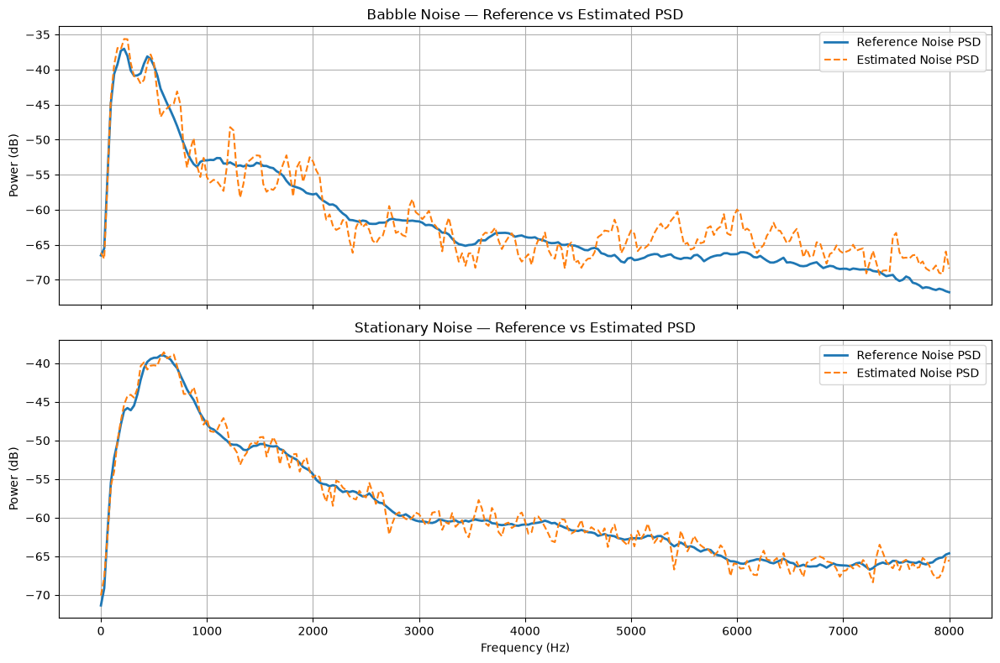

In [73]:
# # Bubble noise PSD plot
# plt.figure(figsize=(12, 5))

# plt.plot(
#     f,
#     10 * np.log10(psd_babble + 1e-12),
#     label="Reference Noise PSD",
#     linewidth=2
# )

# plt.plot(
#     f,
#     10 * np.log10(psd_babble_est + 1e-12),
#     label="Estimated Noise PSD",
#     linestyle="--"
# )

# plt.title("Babble Noise — Reference vs Estimated PSD")
# plt.xlabel("Frequency (Hz)")
# plt.ylabel("Power (dB)")
# plt.legend()
# plt.grid(True)

# plt.show()

# plt.figure(figsize=(12, 5))

# # Stationary noise PSD plot
# plt.plot(
#     f,
#     10 * np.log10(psd_stationary + 1e-12),
#     label="Reference Noise PSD",
#     linewidth=2
# )

# plt.plot(
#     f,
#     10 * np.log10(psd_stationary_est + 1e-12),
#     label="Estimated Noise PSD",
#     linestyle="--"
# )

# plt.title("Stationary Noise — Reference vs Estimated PSD")
# plt.xlabel("Frequency (Hz)")
# plt.ylabel("Power (dB)")
# plt.legend()
# plt.grid(True)

# plt.show()

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Babble noise PSD
axes[0].plot(
    f,
    10 * np.log10(psd_babble + 1e-12),
    label="Reference Noise PSD",
    linewidth=2
)

axes[0].plot(
    f,
    10 * np.log10(psd_babble_est + 1e-12),
    label="Estimated Noise PSD",
    linestyle="--"
)

axes[0].set_title("Babble Noise — Reference vs Estimated PSD")
axes[0].set_ylabel("Power (dB)")
axes[0].legend()
axes[0].grid(True)


# Stationary noise PSD
axes[1].plot(
    f,
    10 * np.log10(psd_stationary + 1e-12),
    label="Reference Noise PSD",
    linewidth=2
)

axes[1].plot(
    f,
    10 * np.log10(psd_stationary_est + 1e-12),
    label="Estimated Noise PSD",
    linestyle="--"
)

axes[1].set_title("Stationary Noise — Reference vs Estimated PSD")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Power (dB)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [33]:
# Estimate speech PSD using estimated noise PSD

speech_psd_babble_est = np.maximum(
    np.abs(Y_babble)**2 - psd_babble_est[:, None],
    0
)

speech_psd_stationary_est = np.maximum(
    np.abs(Y_stationary)**2 - psd_stationary_est[:, None],
    0
)

print("Babble speech PSD:", speech_psd_babble_est.shape)
print("Stationary speech PSD:", speech_psd_stationary_est.shape)

Babble speech PSD: (257, 2258)
Stationary speech PSD: (257, 2258)


In [34]:
# Wiener filtering using estimated noise PSD

S_hat_babble_est, H_babble_est = wiener_filter(
    Y_babble,
    speech_psd_babble_est,
    psd_babble_est
)

S_hat_stationary_est, H_stationary_est = wiener_filter(
    Y_stationary,
    speech_psd_stationary_est,
    psd_stationary_est
)


In [35]:
# Reconstruct speech
# Inverse STFT
_, enhanced_babble_est = istft(
    S_hat_babble_est,
    fs=fs,
    window=window,
    nperseg=nperseg,
    noverlap=noverlap,
    nfft=nfft
)

_, enhanced_stationary_est = istft(
    S_hat_stationary_est,
    fs=fs,
    window=window,
    nperseg=nperseg,
    noverlap=noverlap,
    nfft=nfft
)

# Match original signal length
enhanced_babble_est = enhanced_babble_est[:len(clean_speech)]
enhanced_stationary_est = enhanced_stationary_est[:len(clean_speech)]

print("Enhanced babble:", enhanced_babble_est.shape)
print("Enhanced stationary:", enhanced_stationary_est.shape)

Enhanced babble: (577655,)
Enhanced stationary: (577655,)


In [36]:
import pandas as pd

comparison = []

methods = {
    "Babble": {
        "Noisy": noisy_babble,
        "Reference-noise Wiener": enhanced_babble,
        "Estimated-noise Wiener": enhanced_babble_est
    },
    "Stationary": {
        "Noisy": noisy_stationary,
        "Reference-noise Wiener": enhanced_stationary,
        "Estimated-noise Wiener": enhanced_stationary_est
    }
}

for noise_type, signals in methods.items():

    input_snr = calculate_output_snr(
        clean_speech,
        signals["Noisy"]
    )

    for method, signal in signals.items():

        output_snr = calculate_output_snr(
            clean_speech,
            signal
        )

        comparison.append({
            "Noise Type": noise_type,
            "Method": method,
            "MSE": calculate_mse(clean_speech, signal),
            "RMSE": calculate_rmse(clean_speech, signal),
            "Output SNR (dB)": output_snr,
            "SNR Improvement (dB)": output_snr - input_snr
        })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(4))

,Noise Type,Method,MSE,RMSE,Output SNR (dB),SNR Improvement (dB)
0,Babble,Noisy,0.0029,0.0538,0.0000,0.0000
1,Babble,Reference-noise Wiener,0.0010,0.0311,4.7709,4.7709
2,Babble,Estimated-noise Wiener,0.0009,0.0308,4.8539,4.8539
3,Stationary,Noisy,0.0029,0.0538,-0.0000,0.0000
4,Stationary,Reference-noise Wiener,0.0008,0.0284,5.5528,5.5528
5,Stationary,Estimated-noise Wiener,0.0008,0.0285,5.5348,5.5348


COMMENTS ON RESULTS:
- Wiener filtering improves output SNR for both noise types.
- The stationary noise achieves a greater SNR improvement than babble noise.
- Estimating noise PSD from an initial noise-only snippet can perform comparably to estimating it from the separately available noise recording.

BUT LIMITATION: reference PSD = 36 seconds while estimated PSD = 0.3 seconds

In [37]:
from IPython.display import Audio, display

print("BABBLE NOISE")

print("Original noisy speech:")
display(Audio(noisy_babble, rate=fs, normalize=False))

print("Wiener — Reference noise PSD:")
display(Audio(enhanced_babble, rate=fs, normalize=False))

print("Wiener — Estimated noise PSD:")
display(Audio(enhanced_babble_est, rate=fs, normalize=False))


print("\nSTATIONARY NOISE")

print("Original noisy speech:")
display(Audio(noisy_stationary, rate=fs, normalize=False))

print("Wiener — Reference noise PSD:")
display(Audio(enhanced_stationary, rate=fs, normalize=False))

print("Wiener — Estimated noise PSD:")
display(Audio(enhanced_stationary_est, rate=fs, normalize=False))

BABBLE NOISE
Original noisy speech:


Wiener — Reference noise PSD:


Wiener — Estimated noise PSD:



STATIONARY NOISE
Original noisy speech:


Wiener — Reference noise PSD:


Wiener — Estimated noise PSD:


STEP 8 : IMPROVE PSD ESTIMATION W/ TEMPORAL SMOOTHING
-------------------------------------------------

In [38]:
import numpy as np

def smooth_psd(Y, alpha=0.8):
    """
    Estimate a smoothed power spectrum using
    exponential averaging across time frames.

    Parameters
    ----------
    Y : ndarray
        STFT matrix (frequency x time).
    alpha : float
        Smoothing coefficient between 0 and 1.

    Returns
    -------
    smoothed_psd : ndarray
        Smoothed PSD estimate.
    """

    power = np.abs(Y)**2

    smoothed_psd = np.zeros_like(power)

    # Initialize using first frame
    smoothed_psd[:, 0] = power[:, 0]

    # Exponential smoothing
    for m in range(1, power.shape[1]):

        smoothed_psd[:, m] = (
            alpha * smoothed_psd[:, m-1]
            + (1-alpha) * power[:, m]
        )

    return smoothed_psd

In [39]:
from scipy.signal import istft

alphas = [0, 0.5, 0.8, 0.95]

def smoothed_wiener(Y, noise_psd, alpha):

    # Smooth noisy speech power spectrum
    noisy_psd = smooth_psd(Y, alpha)

    # Estimate speech PSD
    speech_psd = np.maximum(
        noisy_psd - noise_psd[:, None],
        0
    )

    # Calculate Wiener filter
    S_hat, H = wiener_filter(
        Y,
        speech_psd,
        noise_psd
    )

    # Reconstruct signal
    _, enhanced = istft(
        S_hat,
        fs=fs,
        window=window,
        nperseg=nperseg,
        noverlap=noverlap,
        nfft=nfft
    )

    enhanced = enhanced[:len(clean_speech)]

    return enhanced, H

In [40]:
results_smoothing = []

for noise_type, Y, noise_psd in [
    ("Babble", Y_babble, psd_babble_est),
    ("Stationary", Y_stationary, psd_stationary_est)
]:

    for alpha in alphas:

        enhanced, H = smoothed_wiener(
            Y,
            noise_psd,
            alpha
        )

        output_snr = calculate_output_snr(
            clean_speech,
            enhanced
        )

        results_smoothing.append({
            "Noise Type": noise_type,
            "Alpha": alpha,
            "MSE": calculate_mse(clean_speech, enhanced),
            "Output SNR (dB)": output_snr
        })

results_smoothing_df = pd.DataFrame(results_smoothing)

display(results_smoothing_df.round(4))

,Noise Type,Alpha,MSE,Output SNR (dB)
0,Babble,0.00,0.0009,4.8539
1,Babble,0.50,0.0008,5.5133
2,Babble,0.80,0.0007,6.2239
3,Babble,0.95,0.0007,6.4195
4,Stationary,0.00,0.0008,5.5348
5,Stationary,0.50,0.0006,6.5605
6,Stationary,0.80,0.0006,6.9859
7,Stationary,0.95,0.0007,5.9901


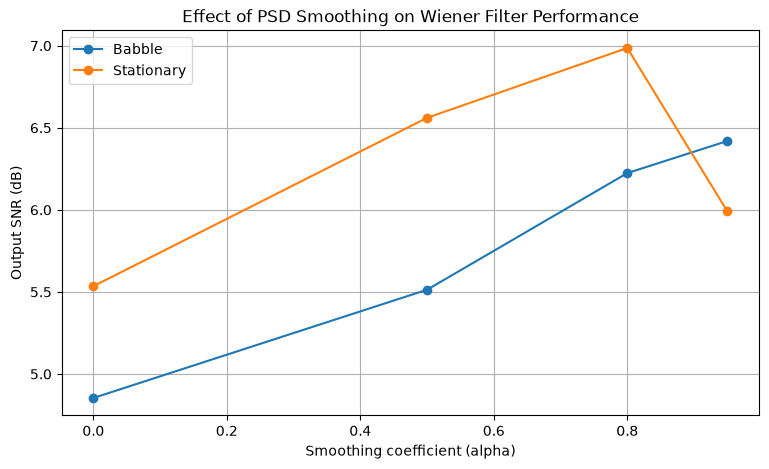

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

for noise_type in ["Babble", "Stationary"]:

    subset = results_smoothing_df[
        results_smoothing_df["Noise Type"] == noise_type
    ]

    plt.plot(
        subset["Alpha"],
        subset["Output SNR (dB)"],
        marker="o",
        label=noise_type
    )

plt.xlabel("Smoothing coefficient (alpha)")
plt.ylabel("Output SNR (dB)")
plt.title("Effect of PSD Smoothing on Wiener Filter Performance")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import stft, istft

# Experimental settings
snr_levels = [-5, 0, 5, 10]

noise_types = {
    "Babble": babble_noise,
    "Stationary": stationary_noise
}

# STFT settings
nperseg = 512
noverlap = 256
nfft = 512
window = "hann"

# Smoothing coefficients
alphas = [0.8, 0.95]

# Initial noise-only segment
noise_duration = 0.5

In [61]:
def run_enhancement(noisy, fs, noise_duration=0.5):

    # 1. Compute STFT
    f, t, Y = stft(
        noisy,
        fs=fs,
        window=window,
        nperseg=nperseg,
        noverlap=noverlap,
        nfft=nfft
    )

    # 2. Estimate noise PSD from initial noise-only segment
    noise_psd = estimate_noise_psd(
        Y, t, noise_duration
    )

    # 3. Estimate instantaneous speech PSD
    speech_psd = np.maximum(
        np.abs(Y)**2 - noise_psd[:, None],
        0
    )

    # 4. Basic Wiener filtering
    S_wiener, _ = wiener_filter(
        Y,
        speech_psd,
        noise_psd
    )

    # 5. Spectral subtraction
    S_sub = spectral_subtraction(
        Y,
        noise_psd
    )

    enhanced_stfts = {
        "Spectral Subtraction": S_sub,
        "Basic Wiener": S_wiener
    }

    # 6. Smoothed Wiener filters
    for alpha in alphas:

        # Estimate smoothed noisy speech PSD
        noisy_psd_smooth = smooth_psd(
            Y, alpha=alpha
        )

        # Estimate speech PSD
        speech_psd_smooth = np.maximum(
            noisy_psd_smooth - noise_psd[:, None],
            0
        )

        # Apply Wiener filter
        S_smooth, _ = wiener_filter(
            Y,
            speech_psd_smooth,
            noise_psd
        )

        enhanced_stfts[f"Smoothed Wiener ({alpha})"] = S_smooth

    # 7. Reconstruct all signals
    enhanced_signals = {}

    for method, S_hat in enhanced_stfts.items():

        _, enhanced = istft(
            S_hat,
            fs=fs,
            window=window,
            nperseg=nperseg,
            noverlap=noverlap,
            nfft=nfft
        )

        enhanced_signals[method] = enhanced[:len(noisy)]

    return enhanced_signals

In [62]:
results = []

for noise_type, noise in noise_types.items():

    for target_snr in snr_levels:

        # Generate noisy speech
        noisy, scaled_noise = add_noise(
            clean_speech,
            noise,
            target_snr
        )

        # Verify input SNR
        actual_input_snr = calculate_output_snr(
            clean_speech,
            noisy
        )

        # Apply all enhancement methods
        enhanced_signals = run_enhancement(
            noisy,
            fs,
            noise_duration=noise_duration
        )

        # Include unprocessed noisy speech as baseline
        enhanced_signals = {
            "Noisy": noisy,
            **enhanced_signals
        }

        # Evaluate each method
        for method, enhanced in enhanced_signals.items():

            mse = calculate_mse(
                clean_speech,
                enhanced
            )

            rmse = calculate_rmse(
                clean_speech,
                enhanced
            )

            output_snr = calculate_output_snr(
                clean_speech,
                enhanced
            )

            snr_improvement = (
                output_snr - actual_input_snr
            )

            results.append({
                "Noise Type": noise_type,
                "Input SNR (dB)": actual_input_snr,
                "Method": method,
                "MSE": mse,
                "RMSE": rmse,
                "Output SNR (dB)": output_snr,
                "SNR Improvement (dB)": snr_improvement
            })

# Convert results into a DataFrame
results_df = pd.DataFrame(results)

display(results_df.round(4))

,Noise Type,Input SNR (dB),Method,MSE,RMSE,Output SNR (dB),SNR Improvement (dB)
0,Babble,-5.0,Noisy,0.0092,0.0958,-5.0000,0.0000
1,Babble,-5.0,Spectral Subtraction,0.0038,0.0618,-1.1918,3.8082
2,Babble,-5.0,Basic Wiener,0.0028,0.0525,0.2264,5.2264
3,Babble,-5.0,Smoothed Wiener (0.8),0.0018,0.0424,2.0809,7.0809
4,Babble,0.0,Noisy,0.0029,0.0538,0.0000,0.0000
5,Babble,0.0,Spectral Subtraction,0.0013,0.0357,3.5814,3.5814
6,Babble,0.0,Basic Wiener,0.0009,0.0308,4.8539,4.8539
7,Babble,0.0,Smoothed Wiener (0.8),0.0007,0.0263,6.2239,6.2239
8,Babble,5.0,Noisy,0.0009,0.0303,5.0000,0.0000
9,Babble,5.0,Spectral Subtraction,0.0004,0.0207,8.2837,3.2837


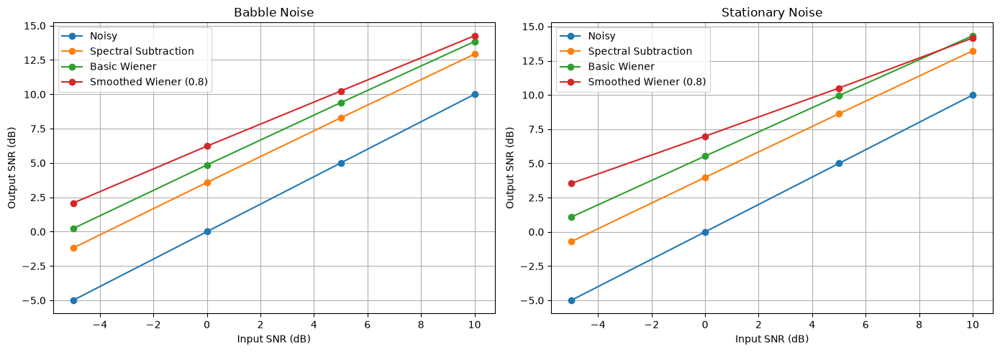

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, noise_type in zip(
    axes,
    ["Babble", "Stationary"]
):

    subset = results_df[
        results_df["Noise Type"] == noise_type
    ]

    for method in subset["Method"].unique():

        method_data = subset[
            subset["Method"] == method
        ].sort_values("Input SNR (dB)")

        ax.plot(
            method_data["Input SNR (dB)"],
            method_data["Output SNR (dB)"],
            marker="o",
            label=method
        )

    ax.set_title(f"{noise_type} Noise")
    ax.set_xlabel("Input SNR (dB)")
    ax.set_ylabel("Output SNR (dB)")
    ax.grid(True)
    ax.legend()

# plt.suptitle(
#     "Speech Enhancement Performance Across Input SNR Levels"
# )

plt.tight_layout()
plt.show()

In [80]:
# fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# for ax, noise_type in zip(
#     axes,
#     ["Babble", "Stationary"]
# ):

#     subset = results_df[
#         (results_df["Noise Type"] == noise_type) &
#         (results_df["Method"] != "Noisy")
#     ]

#     for method in subset["Method"].unique():

#         method_data = subset[
#             subset["Method"] == method
#         ].sort_values("Input SNR (dB)")

#         ax.plot(
#             method_data["Input SNR (dB)"],
#             method_data["SNR Improvement (dB)"],
#             marker="o",
#             label=method
#         )

#     ax.axhline(0, linestyle="--", color="black")

#     ax.set_title(f"{noise_type} Noise")
#     ax.set_xlabel("Input SNR (dB)")
#     ax.set_ylabel("SNR Improvement (dB)")
#     ax.grid(True)
#     ax.legend()

# plt.suptitle("SNR Improvement Across Noise Conditions")

# plt.tight_layout()
# plt.show()

# Get measured noisy speech SNR for each noise type and input SNR
noisy_snr = (
    results_df[results_df["Method"] == "Noisy"]
    .set_index(["Noise Type", "Input SNR (dB)"])["Output SNR (dB)"]
)

# Calculate improvement using measured input SNR
results_df["SNR Improvement (dB)"] = results_df.apply(
    lambda row: (
        row["Output SNR (dB)"]
        - noisy_snr.loc[row["Noise Type"], row["Input SNR (dB)"]]
    ),
    axis=1
)

In [47]:
summary_table = results_df.pivot_table(
    index=[
        "Noise Type",
        "Input SNR (dB)"
    ],
    columns="Method",
    values="Output SNR (dB)"
)

display(summary_table.round(2))

Method                     Basic Wiener  Noisy  Smoothed Wiener (0.8)  \
Noise Type Input SNR (dB)                                               
Babble     -5.000000e+00           0.23   -5.0                   2.08   
            0.000000e+00           4.85    0.0                   6.22   
            5.000000e+00           9.39    5.0                  10.24   
            1.000000e+01          13.84   10.0                  14.26   
Stationary -5.000000e+00           1.08   -5.0                   3.54   
           -1.446491e-15           5.53   -0.0                   6.99   
            5.000000e+00           9.95    5.0                  10.50   
            1.000000e+01          14.32   10.0                  14.16   

Method                     Smoothed Wiener (0.95)  Spectral Subtraction  
Noise Type Input SNR (dB)                                                
Babble     -5.000000e+00                     2.93                 -1.19  
            0.000000e+00                     6.42                  3.58  
            5.000000e+00                     9.90                  8.28  
            1.000000e+01                    13.59                 12.92  
Stationary -5.000000e+00                     3.27                 -0.71  
           -1.446491e-15                     5.99                  3.98  
            5.000000e+00                     9.11                  8.63  
            1.000000e+01                    12.64                 13.22

In [65]:
split_sample = len(clean_speech) // 2

print("Development duration:", split_sample / fs)
print("Evaluation duration:",
      (len(clean_speech) - split_sample) / fs)

Development duration: 18.0516875
Evaluation duration: 18.05175


In [66]:
alphas = [0.5, 0.8, 0.95]

tuning_results = []

for noise_type, noise in noise_types.items():

    for snr in snr_levels:

        noisy, _ = add_noise(clean_speech, noise, snr)

        enhanced_signals = run_enhancement(
            noisy, fs, noise_duration=0.5
        )

        for alpha in alphas:

            enhanced = enhanced_signals[
                f"Smoothed Wiener ({alpha})"
            ]

            # Evaluate development portion only
            output_snr = calculate_output_snr(
                clean_speech[:split_sample],
                enhanced[:split_sample]
            )

            tuning_results.append({
                "Noise Type": noise_type,
                "Input SNR": snr,
                "Alpha": alpha,
                "Development Output SNR": output_snr
            })

tuning_df = pd.DataFrame(tuning_results)

display(tuning_df.round(3))

alpha_summary = (
    tuning_df.groupby("Alpha")["Development Output SNR"]
    .mean()
    .sort_values(ascending=False)
)

display(alpha_summary)

best_alpha = alpha_summary.index[0]

print("Selected smoothing coefficient:", best_alpha)

,Noise Type,Input SNR,Alpha,Development Output SNR
0,Babble,-5,0.50,0.145
1,Babble,-5,0.80,1.547
2,Babble,-5,0.95,2.944
3,Babble,0,0.50,4.610
4,Babble,0,0.80,5.598
5,Babble,0,0.95,6.026
6,Babble,5,0.50,8.934
7,Babble,5,0.80,9.487
8,Babble,5,0.95,9.234
9,Babble,10,0.50,13.207


Alpha
0.80    7.698368
0.95    7.437651
0.50    7.057322
Name: Development Output SNR, dtype: float64

Selected smoothing coefficient: 0.8


In [76]:
# Fix selected coefficient for final evaluation
alphas = [best_alpha]

final_results = []

for noise_type, noise in noise_types.items():

    for snr in snr_levels:

        # Generate noisy speech
        noisy, _ = add_noise(clean_speech, noise, snr)

        # Apply enhancement algorithms
        enhanced_signals = run_enhancement(
            noisy, fs, noise_duration=0.5
        )

        enhanced_signals = {
            "Noisy": noisy,
            **enhanced_signals
        }

        # Evaluate only the held-out half
        clean_test = clean_speech[split_sample:]
        noisy_test = noisy[split_sample:]

        input_snr = calculate_output_snr(
            clean_test, noisy_test
        )

        for method, enhanced in enhanced_signals.items():

            enhanced_test = enhanced[split_sample:]

            output_snr = calculate_output_snr(
                clean_test, enhanced_test
            )

            final_results.append({
                "Noise": noise_type,
                "Target SNR (dB)": snr,
                "Actual Input SNR (dB)": input_snr,
                "Method": method,
                "MSE": calculate_mse(clean_test, enhanced_test),
                "RMSE": calculate_rmse(clean_test, enhanced_test),
                "Output SNR (dB)": output_snr,
                "SNR Improvement (dB)": output_snr - input_snr
            })

# Create final results DataFrame
final_df = pd.DataFrame(final_results)

display(final_df.round(3))

,Noise,Target SNR (dB),Actual Input SNR (dB),Method,MSE,RMSE,Output SNR (dB),SNR Improvement (dB)
0,Babble,-5,-3.779,Noisy,0.009,0.093,-3.779,0.000
1,Babble,-5,-3.779,Spectral Subtraction,0.003,0.057,0.483,4.262
2,Babble,-5,-3.779,Basic Wiener,0.002,0.048,1.955,5.734
3,Babble,-5,-3.779,Smoothed Wiener (0.8),0.002,0.039,3.850,7.629
4,Babble,0,1.221,Noisy,0.003,0.052,1.221,0.000
5,Babble,0,1.221,Spectral Subtraction,0.001,0.033,5.178,3.957
6,Babble,0,1.221,Basic Wiener,0.001,0.029,6.447,5.226
7,Babble,0,1.221,Smoothed Wiener (0.8),0.001,0.025,7.691,6.470
8,Babble,5,6.221,Noisy,0.001,0.029,6.221,0.000
9,Babble,5,6.221,Spectral Subtraction,0.000,0.019,9.820,3.599


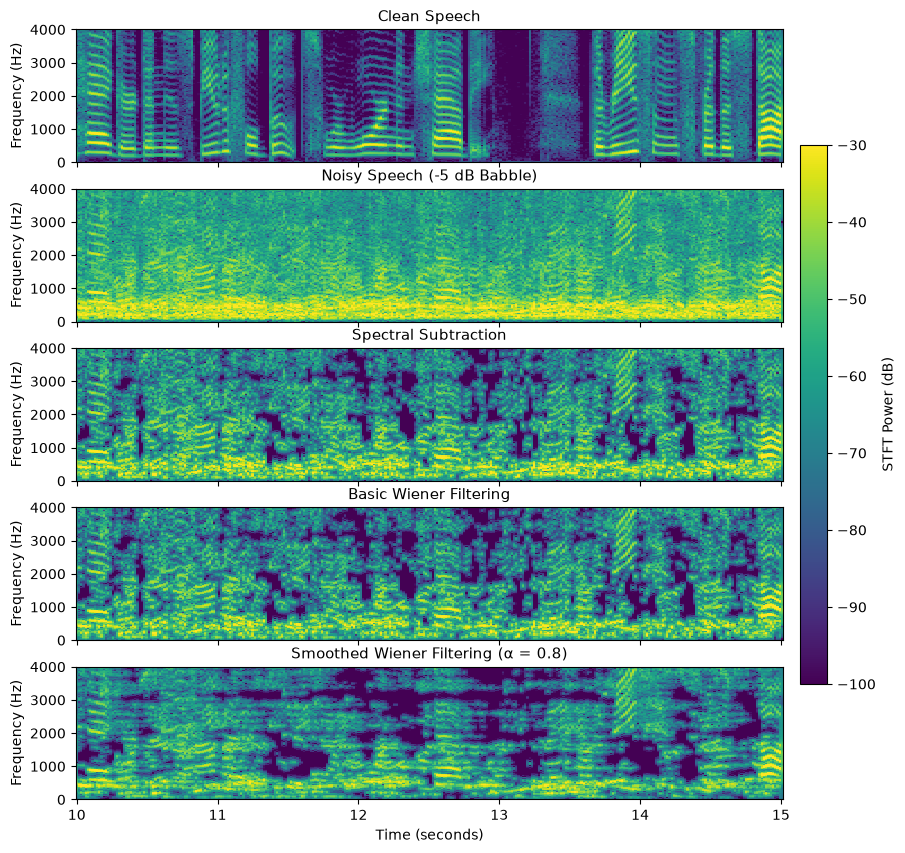

In [75]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import stft

# Experimental settings
target_snr = -5
start_time = 10
end_time = 15

# Generate noisy speech
noisy, _ = add_noise(
    clean_speech,
    babble_noise,
    target_snr
)

# Apply enhancement algorithms
alphas = [0.8]

enhanced_signals = run_enhancement(
    noisy,
    fs,
    noise_duration=0.5
)

# Select representative segment
start = int(start_time * fs)
end = int(end_time * fs)

signals = {
    "Clean Speech": clean_speech[start:end],
    "Noisy Speech (-5 dB Babble)": noisy[start:end],
    "Spectral Subtraction": enhanced_signals["Spectral Subtraction"][start:end],
    "Basic Wiener Filtering": enhanced_signals["Basic Wiener"][start:end],
    "Smoothed Wiener Filtering (α = 0.8)": enhanced_signals["Smoothed Wiener (0.8)"][start:end]
}

# Create figure
fig, axes = plt.subplots(
    5, 1,
    figsize=(11, 10),
    sharex=True,
    sharey=True
)

for ax, (title, signal) in zip(axes, signals.items()):

    # Calculate STFT
    f_plot, t_plot, Z = stft(
        signal,
        fs=fs,
        window="hann",
        nperseg=512,
        noverlap=256,
        nfft=512
    )

    # Convert to dB
    power_db = 10 * np.log10(np.abs(Z)**2 + 1e-12)

    # Plot spectrogram
    im = ax.pcolormesh(
        t_plot + start_time,
        f_plot,
        power_db,
        shading="auto",
        cmap="viridis",
        vmin=-100,
        vmax=-30
    )

    ax.set_title(title, fontsize=11)
    ax.set_ylabel("Frequency (Hz)")
    ax.set_ylim(0, 4000)

axes[-1].set_xlabel("Time (seconds)")

# Shared colorbar
fig.colorbar(
    im,
    ax=axes,
    label="STFT Power (dB)",
    shrink=0.7,
    pad=0.02
)

# Save figure for LaTeX
plt.savefig(
    "qualitative_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [78]:
from IPython.display import Audio, display

# Choose experimental condition
noise_type = "Babble"  # "Babble" or "Stationary"
target_snr = -5         # -5, 0, 5, or 10

# Generate noisy speech
noisy, _ = add_noise(
    clean_speech,
    noise_types[noise_type],
    target_snr
)

# Apply final enhancement algorithms
alphas = [best_alpha]

enhanced_signals = run_enhancement(
    noisy,
    fs,
    noise_duration=0.5
)

# Select the held-out evaluation portion
signals = {
    "Clean Speech": clean_speech[split_sample:],
    "Noisy Speech": noisy[split_sample:],
    "Spectral Subtraction": enhanced_signals["Spectral Subtraction"][split_sample:],
    "Basic Wiener": enhanced_signals["Basic Wiener"][split_sample:],
    f"Smoothed Wiener (α={best_alpha})":
        enhanced_signals[f"Smoothed Wiener ({best_alpha})"][split_sample:]
}

# Play recordings
for name, signal in signals.items():

    print(name)

    display(Audio(
        signal,
        rate=fs,
        normalize=False
    ))

Clean Speech


Noisy Speech


Spectral Subtraction


Basic Wiener


Smoothed Wiener (α=0.8)


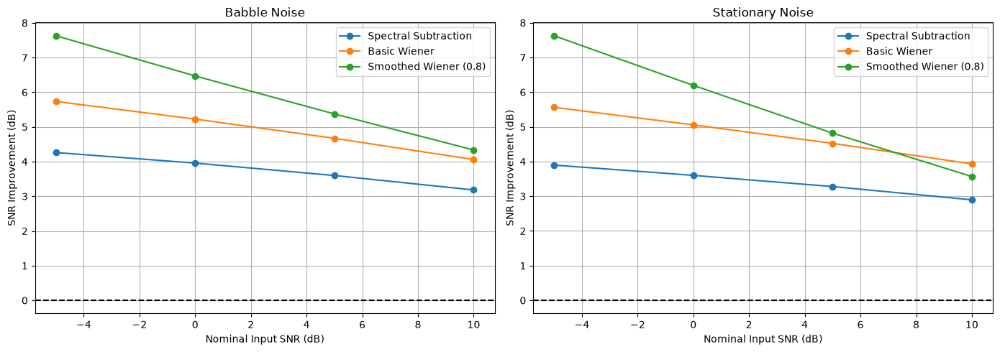

In [82]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, noise_type in zip(axes, ["Babble", "Stationary"]):

    subset = final_df[
        (final_df["Noise"] == noise_type) &
        (final_df["Method"] != "Noisy")
    ]

    for method in subset["Method"].unique():
        method_data = subset[
            subset["Method"] == method
        ].sort_values("Target SNR (dB)")

        ax.plot(
            method_data["Target SNR (dB)"],
            method_data["SNR Improvement (dB)"],
            marker="o",
            label=method
        )

    ax.axhline(0, linestyle="--", color="black")
    ax.set_title(f"{noise_type} Noise")
    ax.set_xlabel("Nominal Input SNR (dB)")
    ax.set_ylabel("SNR Improvement (dB)")
    ax.grid(True)
    ax.legend()

# plt.suptitle("SNR Improvement Across Noise Conditions")
plt.tight_layout()
plt.savefig("snr_improvement.png", dpi=300, bbox_inches="tight")
plt.show()

COMMENTS
- Spectral subtraction has the loudest background noise compared to the other two (matches results)
- Basic wiener sounds very similar to spectral subtraction but just slightly quieter background noise
- Smoothed wiener is noticably the best at removing the background noise. Speech sounds a bit echoey, some words are a bit hard to understand, sounds a bit unintelligible or mumbled